In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training Images :", X_train.shape)
print("Testing Images :", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training Images : (60000, 28, 28)
Testing Images : (10000, 28, 28)


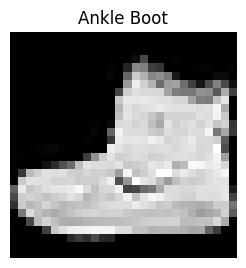

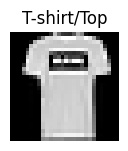

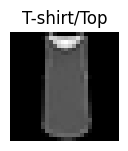

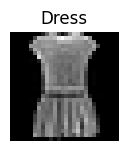

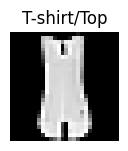

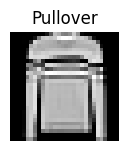

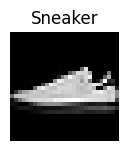

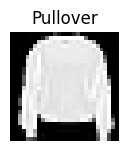

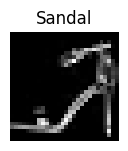

In [3]:
class_names = [
'T-shirt/Top',
'Trouser',
'Pullover',
'Dress',
'Coat',
'Sandal',
'Shirt',
'Sneaker',
'Bag',
'Ankle Boot'
]
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis("off")
    plt.show()

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0
X_train = X_train.reshape(-1,28,28,1)
X_test = X_test.reshape(-1,28,28,1)
print(X_train.shape)

(60000, 28, 28, 1)


In [5]:
model = Sequential([
tf.keras.Input(shape=(28,28,1)),
Conv2D(32,(3,3),activation='relu'),
MaxPooling2D(),
Conv2D(64,(3,3),activation='relu'),
MaxPooling2D(),
Flatten(),
Dense(128,activation='relu'),
Dropout(0.5),
Dense(10,activation='softmax')
    ])
model.compile(
optimizer='adam',
loss='sparse_categorical_crossentropy',
metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
X_train,
y_train,
validation_split=0.3,
epochs=5,
batch_size=32
)
loss, accuracy = model.evaluate(X_test, y_test)
print("Loss :", loss)
print("Accuracy :", accuracy)

Epoch 1/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - accuracy: 0.7880 - loss: 0.5937 - val_accuracy: 0.8618 - val_loss: 0.3838
Epoch 2/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8564 - loss: 0.4020 - val_accuracy: 0.8732 - val_loss: 0.3409
Epoch 3/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8726 - loss: 0.3526 - val_accuracy: 0.8893 - val_loss: 0.3019
Epoch 4/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8838 - loss: 0.3182 - val_accuracy: 0.8958 - val_loss: 0.2819
Epoch 5/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8943 - loss: 0.2950 - val_accuracy: 0.8886 - val_loss: 0.3018
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8784 - loss: 0.3168
Loss : 0.3167828917503357
Accuracy : 0.8784000277519226


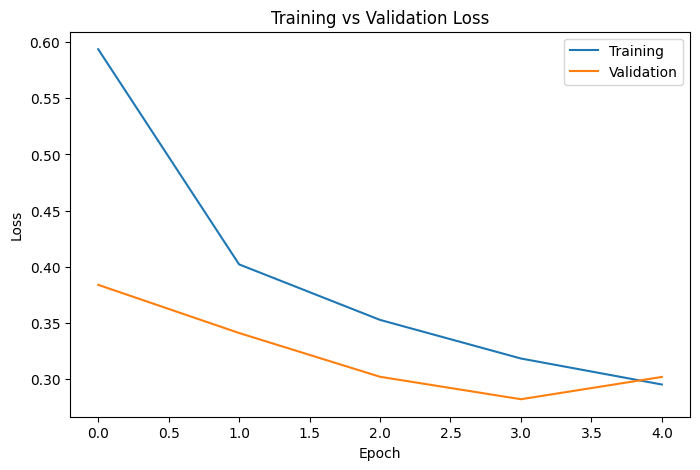

In [7]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'],label='Training')
plt.plot(history.history['val_loss'],label='Validation')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


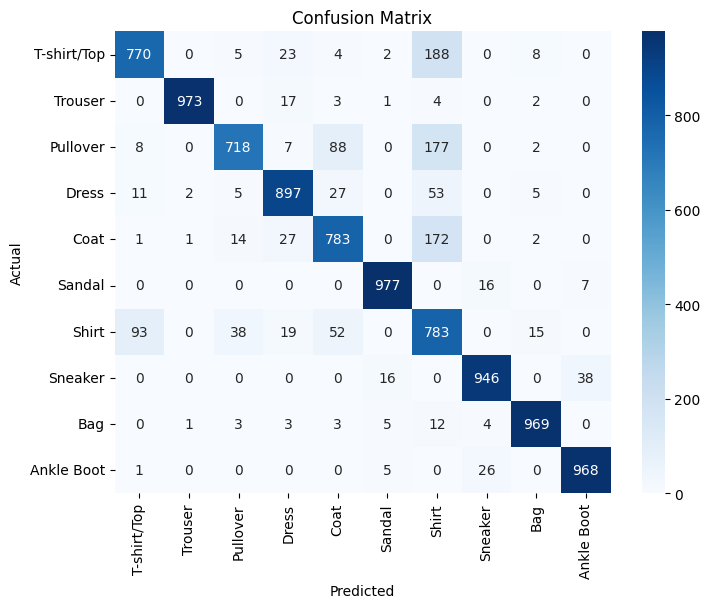

In [8]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns
pred = model.predict(X_test)
pred_classes = np.argmax(pred, axis=1)
cm = confusion_matrix(y_test, pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(
cm,
annot=True,
fmt='d',
cmap='Blues',
xticklabels=class_names,
yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [9]:
print(classification_report(
y_test,
pred_classes,
target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/Top       0.87      0.77      0.82      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.92      0.72      0.81      1000
       Dress       0.90      0.90      0.90      1000
        Coat       0.82      0.78      0.80      1000
      Sandal       0.97      0.98      0.97      1000
       Shirt       0.56      0.78      0.66      1000
     Sneaker       0.95      0.95      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle Boot       0.96      0.97      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.89      0.88      0.88     10000
weighted avg       0.89      0.88      0.88     10000



313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


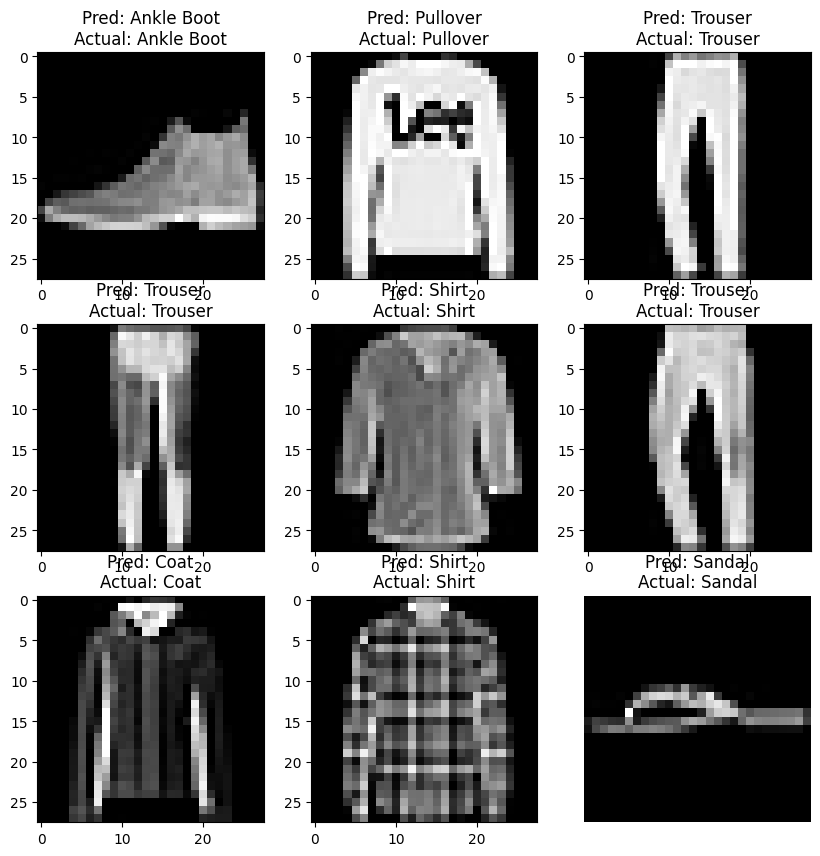

In [10]:
pred = model.predict(X_test)
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_test[i].reshape(28,28), cmap='gray')
    plt.title(
    "Pred: " + class_names[np.argmax(pred[i])] +
    "\nActual: " + class_names[y_test[i]]
    )
plt.axis("off")
plt.show()